## Objetivo

Comparar quatro modelos com semanas historicas consolidadas e ajustar os parametros com validacao temporal

## 1  Preparar ambiente

In [1]:
%pip install -q billboard-charts==0.2.0 pandas numpy scikit-learn matplotlib joblib

## 2  Imports e configuracao

In [2]:
from datetime import datetime, timedelta
from pathlib import Path
from zoneinfo import ZoneInfo
import json
import re
import unicodedata

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from billboard_charts import backfill, make_session
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

CHART_SLUG = "alternative-airplay"
FIRST_WEEK = "2023-10-21"
HOLDOUT_WEEKS = 12
VALIDATION_WEEKS = 4
MIN_TRAIN_WEEKS = 26

DATA_DIR = Path("data")
REPORTS_DIR = Path("reports")
MODELS_DIR = Path("models")
DATA_PATH = DATA_DIR / "alternative_airplay.csv"

for folder in [DATA_DIR, REPORTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

FEATURES = [
    "rank",
    "last_week_rank",
    "peak_position",
    "weeks_on_chart",
    "rank_movement",
    "rank_two_weeks_ago",
    "rank_movement_2w",
    "has_two_week_history",
    "is_first_week",
]

## 3  Atualizar historico

Na primeira execucao busca as semanas desde outubro de 2023 e nas proximas execucoes busca apenas semanas ausentes

In [3]:
def last_saturday(today=None):
    if today is None:
        today = datetime.now(ZoneInfo("America/Sao_Paulo")).date()
    return today - timedelta(days=(today.weekday() - 5) % 7)

end_week = last_saturday().isoformat()

refresh = backfill(
    slug=CHART_SLUG,
    csv_path=DATA_PATH,
    first_week=FIRST_WEEK,
    last_week=end_week,
    session=make_session(),
    checkpoint_every=12,
    max_attempts=3,
)

print(f"Semanas no arquivo: {refresh.weeks}")
print(f"Semanas adicionadas: {len(refresh.written)}")
print(f"Semanas indisponiveis ou com falha: {len(refresh.failed)}")
print(f"Ultima semana coletada: {refresh.last}")

Semanas no arquivo: 157
Semanas adicionadas: 157
Semanas indisponiveis ou com falha: 0
Ultima semana coletada: 2026-10-17


## 4  Validar dados

In [4]:
if not DATA_PATH.exists():
    raise FileNotFoundError("Historico nao foi criado")

raw = pd.read_csv(DATA_PATH)
rename_map = {
    "Date": "date",
    "Rank": "rank",
    "Song": "song",
    "Artist": "artist",
    "Last Week": "last_week_rank",
    "Peak Position": "peak_position",
    "Weeks on Chart": "weeks_on_chart",
}
raw = raw.rename(columns=rename_map)
required = list(rename_map.values())
missing = [col for col in required if col not in raw.columns]
if missing:
    raise ValueError(f"Colunas ausentes: {missing}")

raw["date"] = pd.to_datetime(raw["date"], errors="coerce").dt.normalize()
for col in ["rank", "last_week_rank", "peak_position", "weeks_on_chart"]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")

raw = raw.dropna(subset=["date", "rank", "song", "artist"]).copy()
raw["last_week_rank"] = raw["last_week_rank"].fillna(0)
raw["peak_position"] = raw["peak_position"].fillna(raw["rank"])
raw["weeks_on_chart"] = raw["weeks_on_chart"].fillna(1)

for col in ["rank", "last_week_rank", "peak_position", "weeks_on_chart"]:
    raw[col] = raw[col].astype(int)


def normalize_identity(value):
    value = unicodedata.normalize("NFKD", str(value))
    value = "".join(char for char in value if not unicodedata.combining(char))
    return re.sub(r"[^a-z0-9]+", "", value.lower())

raw["song_key"] = raw["song"].map(normalize_identity) + "|" + raw["artist"].map(normalize_identity)
raw = raw.sort_values(["date", "rank"])
raw = raw.drop_duplicates(["date", "song_key"], keep="first")
raw = raw.drop_duplicates(["date", "rank"], keep="first")
raw = raw.sort_values(["date", "rank"]).reset_index(drop=True)

chart_dates = sorted(raw["date"].unique())
if len(chart_dates) < 60:
    raise ValueError("Historico curto demais para um backtest temporal confiavel")

latest_date = raw["date"].max()
print(f"Linhas: {len(raw):,}")
print(f"Semanas: {len(chart_dates)}")
print(f"Periodo: {raw['date'].min().date()} ate {latest_date.date()}")

latest_chart = raw[raw["date"] == latest_date].sort_values("rank")
display(latest_chart[["rank", "song", "artist", "last_week_rank", "peak_position", "weeks_on_chart"]].head(15))

Linhas: 6,280
Semanas: 157
Periodo: 2023-10-21 ate 2026-10-17


,rank,song,artist,last_week_rank,peak_position,weeks_on_chart
6240,1,Self Aware,Temper City,2,1,1
6241,2,Beaches In Tennessee,Cage the Elephant,1,1,1
6242,3,We Might As Well Be Strangers,Weezer Featuring Wednesday,4,3,1
6243,4,Fool's Gold,Buffalo Traffic Jam,3,3,1
6244,5,Babydoll,Dominic Fike,5,5,1
6245,6,Loser,Tame Impala,7,6,1
6246,7,In My Room,Julia Wolf,6,2,1
6247,8,no more regrets,almost monday,8,8,1
6248,9,Freakin' Out,Dexter And The Moonrocks,10,1,1
6249,10,Window,Foo Fighters,11,10,1


## 5  Criar variaveis

Usamos apenas informacoes disponiveis na semana da previsao

In [5]:
features = raw.copy()

two_weeks_ago = raw[["date", "song_key", "rank"]].copy()
two_weeks_ago["date"] = two_weeks_ago["date"] + pd.Timedelta(days=14)
two_weeks_ago = two_weeks_ago.rename(columns={"rank": "rank_two_weeks_ago"})

features = features.merge(two_weeks_ago, on=["date", "song_key"], how="left")
features["rank_movement"] = np.where(
    features["last_week_rank"] > 0,
    features["last_week_rank"] - features["rank"],
    0,
)
features["rank_movement_2w"] = features["rank_two_weeks_ago"] - features["rank"]
features["has_two_week_history"] = features["rank_two_weeks_ago"].notna().astype(int)
features["rank_two_weeks_ago"] = features["rank_two_weeks_ago"].fillna(0)
features["rank_movement_2w"] = features["rank_movement_2w"].fillna(0)
features["is_first_week"] = (features["weeks_on_chart"] == 1).astype(int)

future = raw[["date", "song_key"]].copy()
future["date"] = future["date"] - pd.Timedelta(days=7)
future["stays_next_week"] = 1
labeled = features.merge(future, on=["date", "song_key"], how="left")

available_dates = set(raw["date"].unique())
valid_transition_dates = {
    date for date in available_dates
    if date + pd.Timedelta(days=7) in available_dates
}
labeled = labeled[labeled["date"].isin(valid_transition_dates)].copy()
labeled["target_stays"] = labeled["stays_next_week"].fillna(0).astype(int)
labeled = labeled.sort_values(["date", "rank"]).reset_index(drop=True)

print(f"Amostras rotuladas: {len(labeled):,}")
print(f"Semanas rotuladas: {labeled['date'].nunique()}")
print(f"Taxa historica de permanencia: {labeled['target_stays'].mean():.1%}")

Amostras rotuladas: 6,240
Semanas rotuladas: 156
Taxa historica de permanencia: 93.6%


## 6  Separar semanas de teste

As ultimas 12 semanas ficam fora do ajuste e servem para avaliar previsoes historicas

In [6]:
all_weeks = sorted(labeled["date"].unique())
if len(all_weeks) < HOLDOUT_WEEKS + MIN_TRAIN_WEEKS + 8:
    raise ValueError("Poucas semanas para separar treino validacao e teste")

test_weeks = set(all_weeks[-HOLDOUT_WEEKS:])
development = labeled[~labeled["date"].isin(test_weeks)].copy().reset_index(drop=True)
test = labeled[labeled["date"].isin(test_weeks)].copy().reset_index(drop=True)

X_dev = development[FEATURES]
y_dev = development["target_stays"]
X_test = test[FEATURES]
y_test = test["target_stays"]

print(f"Semanas de treino e validacao: {development['date'].nunique()}")
print(f"Semanas de teste: {test['date'].nunique()}")
print(f"Teste: {test['date'].min().date()} ate {test['date'].max().date()}")

Semanas de treino e validacao: 144
Semanas de teste: 12
Teste: 2026-07-25 ate 2026-10-10


## 7  Ajustar modelos

A validacao usa semanas futuras em cada rodada e escolhe os parametros pelo F1 medio

In [7]:
def make_temporal_splits(frame, n_splits=4, validation_weeks=4, min_train_weeks=26):
    weeks = np.array(sorted(frame["date"].unique()))
    possible = (len(weeks) - min_train_weeks) // validation_weeks
    n_splits = min(n_splits, possible)
    if n_splits < 2:
        raise ValueError("Historico insuficiente para validacao temporal")

    starts = np.linspace(
        min_train_weeks,
        len(weeks) - validation_weeks,
        n_splits,
        dtype=int,
    )
    splits = []
    for start in starts:
        train_weeks = set(weeks[:start])
        valid_weeks = set(weeks[start:start + validation_weeks])
        train_idx = np.flatnonzero(frame["date"].isin(train_weeks).to_numpy())
        valid_idx = np.flatnonzero(frame["date"].isin(valid_weeks).to_numpy())
        if len(train_idx) and len(valid_idx):
            splits.append((train_idx, valid_idx))
    return splits

cv_splits = make_temporal_splits(development, validation_weeks=VALIDATION_WEEKS, min_train_weeks=MIN_TRAIN_WEEKS)
print(f"Rodadas de validacao temporal: {len(cv_splits)}")

models = {
    "Regressao logistica": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)),
        ]),
        {"model__C": [0.1, 1.0, 10.0]},
    ),
    "Random Forest": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1)),
        ]),
        {"model__max_depth": [4, 8, None], "model__min_samples_leaf": [2, 5]},
    ),
    "KNN": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier()),
        ]),
        {"model__n_neighbors": [5, 11, 21], "model__weights": ["uniform", "distance"]},
    ),
    "Gradient Boosting": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", GradientBoostingClassifier(random_state=42)),
        ]),
        {"model__n_estimators": [100, 200], "model__learning_rate": [0.03, 0.1], "model__max_depth": [1, 2]},
    ),
}

searches = {}
for name, (pipeline, param_grid) in models.items():
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1",
        cv=cv_splits,
        n_jobs=-1,
        refit=True,
        error_score="raise",
    )
    search.fit(X_dev, y_dev)
    searches[name] = search
    print(f"{name}: CV F1 = {search.best_score_:.3f} | parametros = {search.best_params_}")

Rodadas de validacao temporal: 4
Regressao logistica: CV F1 = 0.895 | parametros = {'model__C': 10.0}
Random Forest: CV F1 = 0.943 | parametros = {'model__max_depth': None, 'model__min_samples_leaf': 2}
KNN: CV F1 = 0.969 | parametros = {'model__n_neighbors': 21, 'model__weights': 'uniform'}
Gradient Boosting: CV F1 = 0.970 | parametros = {'model__learning_rate': 0.1, 'model__max_depth': 1, 'model__n_estimators': 100}


## 8  Comparar com semanas reais

O teste usa semanas que nao participaram da escolha dos parametros e inclui um baseline que sempre preve permanencia

In [8]:
def calculate_metrics(y_true, y_pred, y_score):
    try:
        roc_auc = roc_auc_score(y_true, y_score)
    except ValueError:
        roc_auc = np.nan
    try:
        pr_auc = average_precision_score(y_true, y_score)
    except ValueError:
        pr_auc = np.nan
    return {
        "acuracia": accuracy_score(y_true, y_pred),
        "precisao": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
    }

comparison = []
test_prediction_rows = []

for name, search in searches.items():
    model = search.best_estimator_
    prediction = model.predict(X_test)
    score = model.predict_proba(X_test)[:, 1]
    metrics = calculate_metrics(y_test, prediction, score)
    comparison.append({"modelo": name, "cv_f1": search.best_score_, **metrics})

    rows = test[["date", "rank", "song", "artist", "target_stays"]].copy()
    rows["modelo"] = name
    rows["previsao_permanece"] = prediction
    rows["score_permanencia"] = score
    test_prediction_rows.append(rows)

baseline_prediction = np.ones(len(test), dtype=int)
baseline_metrics = calculate_metrics(y_test, baseline_prediction, baseline_prediction.astype(float))
comparison.append({"modelo": "Baseline sempre permanece", "cv_f1": np.nan, **baseline_metrics})

comparison = pd.DataFrame(comparison).sort_values("cv_f1", ascending=False, na_position="last").reset_index(drop=True)
test_predictions = pd.concat(test_prediction_rows, ignore_index=True)
display(comparison.round(3))

,modelo,cv_f1,acuracia,precisao,recall,f1,roc_auc,pr_auc
0,Gradient Boosting,0.970,0.960,0.962,0.998,0.980,0.918,0.994
1,KNN,0.969,0.962,0.964,0.998,0.981,0.898,0.990
2,Random Forest,0.943,0.921,0.984,0.932,0.957,0.908,0.993
3,Regressao logistica,0.895,0.860,0.995,0.857,0.921,0.934,0.996
4,Baseline sempre permanece,NaN,0.950,0.950,1.000,0.974,0.500,0.950


## 9  Ver desempenho semana a semana

,date,musicas_avaliadas,taxa_real_permanencia,f1,acuracia
0,2026-07-25,40.0,0.975,1.000,1.000
1,2026-08-01,40.0,0.975,0.987,0.975
2,2026-08-08,40.0,0.950,0.987,0.975
3,2026-08-15,40.0,0.900,0.973,0.950
4,2026-08-22,40.0,0.950,0.974,0.950
5,2026-08-29,40.0,0.950,0.974,0.950
6,2026-09-05,40.0,0.950,0.961,0.925
7,2026-09-12,40.0,0.950,0.987,0.975
8,2026-09-19,40.0,0.950,0.974,0.950
9,2026-09-26,40.0,0.975,0.987,0.975


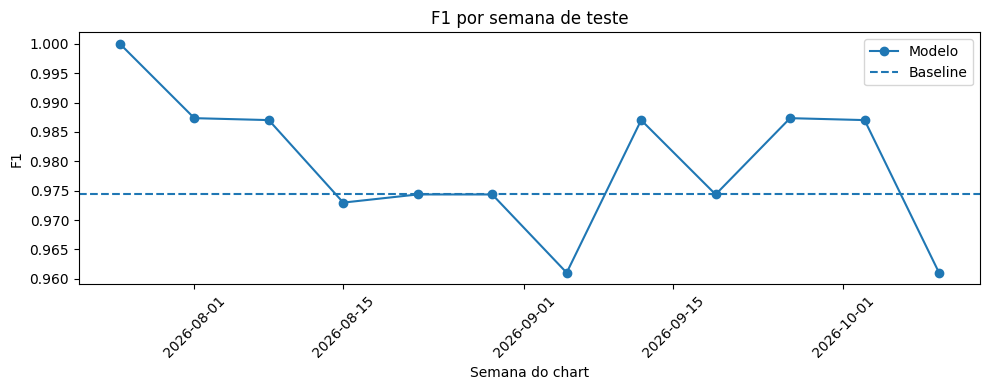

In [9]:
best_name = max(searches, key=lambda name: searches[name].best_score_)
best_test = test_predictions[test_predictions["modelo"] == best_name].copy()

weekly_results = (
    best_test.groupby("date")
    .apply(lambda group: pd.Series({
        "musicas_avaliadas": len(group),
        "taxa_real_permanencia": group["target_stays"].mean(),
        "f1": f1_score(group["target_stays"], group["previsao_permanece"], zero_division=0),
        "acuracia": accuracy_score(group["target_stays"], group["previsao_permanece"]),
    }), include_groups=False)
    .reset_index()
)

display(weekly_results.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weekly_results["date"], weekly_results["f1"], marker="o", label="Modelo")
ax.axhline(baseline_metrics["f1"], linestyle="--", label="Baseline")
ax.set_title("F1 por semana de teste")
ax.set_ylabel("F1")
ax.set_xlabel("Semana do chart")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 10  Escolher e treinar o modelo final

A escolha usa o F1 da validacao temporal e depois treina com todo o historico rotulado

In [10]:
best_name = max(searches, key=lambda name: searches[name].best_score_)
final_model = clone(searches[best_name].best_estimator_)
final_model.fit(labeled[FEATURES], labeled["target_stays"])

print(f"Modelo selecionado: {best_name}")
print(f"F1 medio na validacao temporal: {searches[best_name].best_score_:.3f}")
print(f"F1 no teste final: {comparison.loc[comparison['modelo'] == best_name, 'f1'].iloc[0]:.3f}")
print(f"F1 do baseline: {baseline_metrics['f1']:.3f}")

if comparison.loc[comparison["modelo"] == best_name, "f1"].iloc[0] <= baseline_metrics["f1"]:
    print("O modelo ainda nao superou o baseline no teste final")

Modelo selecionado: Gradient Boosting
F1 medio na validacao temporal: 0.970
F1 no teste final: 0.980
F1 do baseline: 0.974


## 11  Prever a proxima semana

O score indica a chance estimada de cada musica atual continuar no Top 40 e nao cobre novas entradas

In [11]:
latest_date = features["date"].max()
latest_features = features[features["date"] == latest_date].copy().sort_values("rank")
latest_scores = final_model.predict_proba(latest_features[FEATURES])[:, 1]
latest_predictions = final_model.predict(latest_features[FEATURES])

forecast = latest_features[["date", "rank", "song", "artist", "weeks_on_chart"]].copy()
forecast = forecast.rename(columns={"date": "chart_atual", "rank": "posicao_atual"})
forecast["semana_prevista"] = (latest_date + pd.Timedelta(days=7)).date().isoformat()
forecast["score_permanencia_pct"] = np.round(latest_scores * 100, 1)
forecast["previsao_permanece"] = np.where(latest_predictions == 1, "Sim", "Nao")
forecast = forecast.sort_values("score_permanencia_pct", ascending=False).reset_index(drop=True)

display(forecast[["semana_prevista", "posicao_atual", "song", "artist", "score_permanencia_pct", "previsao_permanece"]])

,semana_prevista,posicao_atual,song,artist,score_permanencia_pct,previsao_permanece
0,2026-10-24,1,Self Aware,Temper City,99.3,Sim
1,2026-10-24,3,We Might As Well Be Strangers,Weezer Featuring Wednesday,99.3,Sim
2,2026-10-24,6,Loser,Tame Impala,99.3,Sim
3,2026-10-24,5,Babydoll,Dominic Fike,99.2,Sim
4,2026-10-24,8,no more regrets,almost monday,99.1,Sim
5,2026-10-24,9,Freakin' Out,Dexter And The Moonrocks,99.0,Sim
6,2026-10-24,25,Exit Signs,LEAP,98.9,Sim
7,2026-10-24,28,High,In Color,98.9,Sim
8,2026-10-24,30,F.T.R.,Sublime,98.7,Sim
9,2026-10-24,4,Fool's Gold,Buffalo Traffic Jam,98.7,Sim


## 12  Salvar resultados

Os arquivos ficam prontos para uso no deploy e para acompanhar as atualizacoes semanais

In [12]:
comparison.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)
weekly_results.to_csv(REPORTS_DIR / "weekly_backtest.csv", index=False)
test_predictions.to_csv(REPORTS_DIR / "test_predictions.csv", index=False)
forecast.to_csv(REPORTS_DIR / "forecast_next_week.csv", index=False)

model_bundle = {
    "model": final_model,
    "model_name": best_name,
    "features": FEATURES,
    "chart_slug": CHART_SLUG,
    "trained_through_chart_date": latest_date.date().isoformat(),
}
joblib.dump(model_bundle, MODELS_DIR / "altchart_model.joblib")

metadata = {
    "model_name": best_name,
    "best_parameters": searches[best_name].best_params_,
    "cv_f1": float(searches[best_name].best_score_),
    "test_f1": float(comparison.loc[comparison["modelo"] == best_name, "f1"].iloc[0]),
    "baseline_test_f1": float(baseline_metrics["f1"]),
    "trained_through_chart_date": latest_date.date().isoformat(),
    "forecast_for": (latest_date + pd.Timedelta(days=7)).date().isoformat(),
    "features": FEATURES,
    "source": "Billboard Alternative Airplay",
}
with open(MODELS_DIR / "model_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print("Resultados salvos em data reports e models")

Resultados salvos em data reports e models
